In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 120

os.makedirs("data", exist_ok=True)
os.makedirs("charts", exist_ok=True)

print("Working folder:", os.getcwd())


Working folder: /workspaces/Indian_market


In [3]:
#.......Data Acquisation.........
RAW_PATH = "data/NIFTY50_stock_history.csv"

if not os.path.exists(RAW_PATH):
    raw = yf.download(
        "^NSEI",
        start="2016-06-01",
        end="2026-07-01",      # end is exclusive, so this includes 30 June 2026
        auto_adjust=False,
        progress=False,
    )
    raw.columns = raw.columns.get_level_values(0)
    raw = raw.reset_index()[["Date", "Adj Close", "Close", "High", "Low", "Open", "Volume"]]
    raw.to_csv(RAW_PATH, index=False)
    print("Downloaded and saved.")
else:
    print("File already exists, skipping download.")

File already exists, skipping download.


In [4]:
#....First look of data.......
df_raw = pd.read_csv(RAW_PATH)
df = df_raw.copy()          # work on a copy, keep df_raw untouched

print("Shape:", df.shape)
print()
df.info()
print()
df.head()


Shape: (2483, 7)

<class 'pandas.DataFrame'>
RangeIndex: 2483 entries, 0 to 2482
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       2483 non-null   str    
 1   Adj Close  2483 non-null   float64
 2   Close      2483 non-null   float64
 3   High       2483 non-null   float64
 4   Low        2483 non-null   float64
 5   Open       2483 non-null   float64
 6   Volume     2483 non-null   int64  
dtypes: float64(5), int64(1), str(1)
memory usage: 135.9 KB



,Date,Adj Close,Close,High,Low,Open,Volume
0,2016-06-01,8179.950195,8179.950195,8215.349609,8171.049805,8179.200195,194400
1,2016-06-02,8218.950195,8218.950195,8229.500000,8154.750000,8156.899902,181700
2,2016-06-03,8220.799805,8220.799805,8262.000000,8209.849609,8246.200195,379000
3,2016-06-06,8201.049805,8201.049805,8234.700195,8186.049805,8228.750000,171600
4,2016-06-07,8266.450195,8266.450195,8294.950195,8216.400391,8235.549805,241900


In [5]:
df.tail()

,Date,Adj Close,Close,High,Low,Open,Volume
2478,2026-06-23,23824.099609,23824.099609,24135.500000,23784.949219,24071.300781,340100
2479,2026-06-24,24021.650391,24021.650391,24090.050781,23789.250000,23795.800781,395600
2480,2026-06-25,24056.000000,24056.000000,24261.599609,24039.000000,24125.849609,448800
2481,2026-06-29,23946.250000,23946.250000,24120.000000,23924.550781,24061.750000,588500
2482,2026-06-30,23865.750000,23865.750000,24035.550781,23829.199219,24032.050781,449000


In [6]:
#.....data quality audit.......
print("Missing values per column:")
print(df.isnull().sum())

print("\nExact duplicate rows:", df.duplicated().sum())
print("Duplicate dates:", df["Date"].duplicated().sum())

print("\nRows with Volume == 0:", (df["Volume"] == 0).sum(),
      f"({(df['Volume'] == 0).mean():.1%} of rows)")

# Price consistency: High must be the highest, Low the lowest
bad = df[(df["High"] < df["Low"]) |
         (df["High"] < df["Open"]) | (df["High"] < df["Close"]) |
         (df["Low"] > df["Open"]) | (df["Low"] > df["Close"])]
print("Rows failing OHLC consistency check:", len(bad))

Missing values per column:
Date         0
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64

Exact duplicate rows: 0
Duplicate dates: 0

Rows with Volume == 0: 28 (1.1% of rows)
Rows failing OHLC consistency check: 0


In [16]:
#...cleaning......
# Create a copy before cleaning
df_clean = df.copy()
# Date column to datetime
df_clean["Date"] = pd.to_datetime(df_clean["Date"])
df_clean = df_clean.sort_values("Date")
df_clean = df_clean.reset_index(drop=True)
print("Rows after cleaning:", len(df_clean))
df_clean["Volume"] = df_clean["Volume"].replace(0, np.nan)
print("Zero-volume rows set to NaN:", df_clean["Volume"].isnull().sum())
df_clean.head()

Rows after cleaning: 2483
Zero-volume rows set to NaN: 28


,Date,Adj Close,Close,High,Low,Open,Volume
0,2016-06-01,8179.950195,8179.950195,8215.349609,8171.049805,8179.200195,194400.0
1,2016-06-02,8218.950195,8218.950195,8229.500000,8154.750000,8156.899902,181700.0
2,2016-06-03,8220.799805,8220.799805,8262.000000,8209.849609,8246.200195,379000.0
3,2016-06-06,8201.049805,8201.049805,8234.700195,8186.049805,8228.750000,171600.0
4,2016-06-07,8266.450195,8266.450195,8294.950195,8216.400391,8235.549805,241900.0


In [8]:
#...cleaning verfication.....
print("Missing Values After Cleaning:")
print(df_clean.isnull().sum())

print("\nDuplicate Dates:")
print(df_clean["Date"].duplicated().sum())

print("\nDate Range:")
print(df_clean["Date"].min())
print(df_clean["Date"].max())

Missing Values After Cleaning:
Date          0
Adj Close     0
Close         0
High          0
Low           0
Open          0
Volume       28
dtype: int64

Duplicate Dates:
0

Date Range:
2016-06-01 00:00:00
2026-06-30 00:00:00


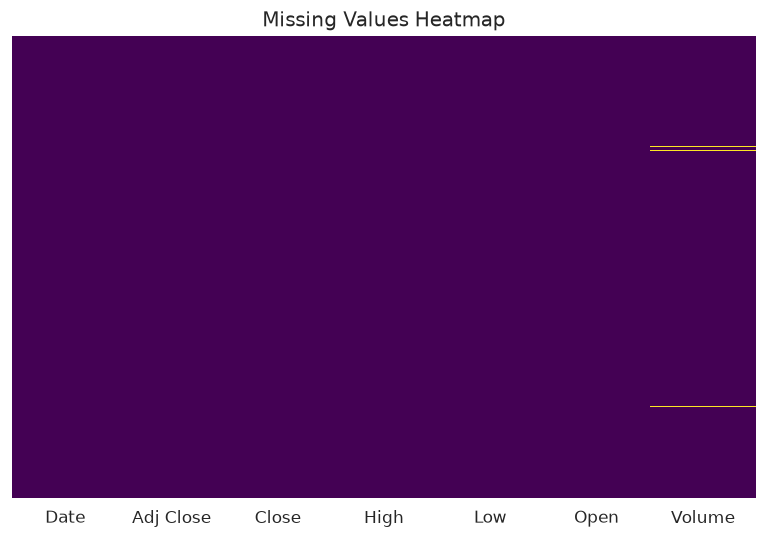

In [9]:
#missing values visualization
plt.figure(figsize=(8,5))

sns.heatmap(
    df_clean.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values Heatmap")
plt.show()

In [10]:
#feature_for_upcoming 
#1. Daily percentage return
df_clean["Daily_Return_%"] = (
    df_clean["Close"].pct_change() * 100
)

#2. 50-day moving average
df_clean["MA_50"] = (
    df_clean["Close"]
    .rolling(window=50)
    .mean()
)

#3. 200-day moving average
df_clean["MA_200"] = (
    df_clean["Close"]
    .rolling(window=200)
    .mean()
)

#4. Calendar year
df_clean["Year"] = df_clean["Date"].dt.year

df_clean.head()

,Date,Adj Close,Close,High,Low,Open,Volume,Daily_Return_%,MA_50,MA_200,Year
0,2016-06-01,8179.950195,8179.950195,8215.349609,8171.049805,8179.200195,194400.0,NaN,NaN,NaN,2016
1,2016-06-02,8218.950195,8218.950195,8229.500000,8154.750000,8156.899902,181700.0,0.476776,NaN,NaN,2016
2,2016-06-03,8220.799805,8220.799805,8262.000000,8209.849609,8246.200195,379000.0,0.022504,NaN,NaN,2016
3,2016-06-06,8201.049805,8201.049805,8234.700195,8186.049805,8228.750000,171600.0,-0.240244,NaN,NaN,2016
4,2016-06-07,8266.450195,8266.450195,8294.950195,8216.400391,8235.549805,241900.0,0.797464,NaN,NaN,2016


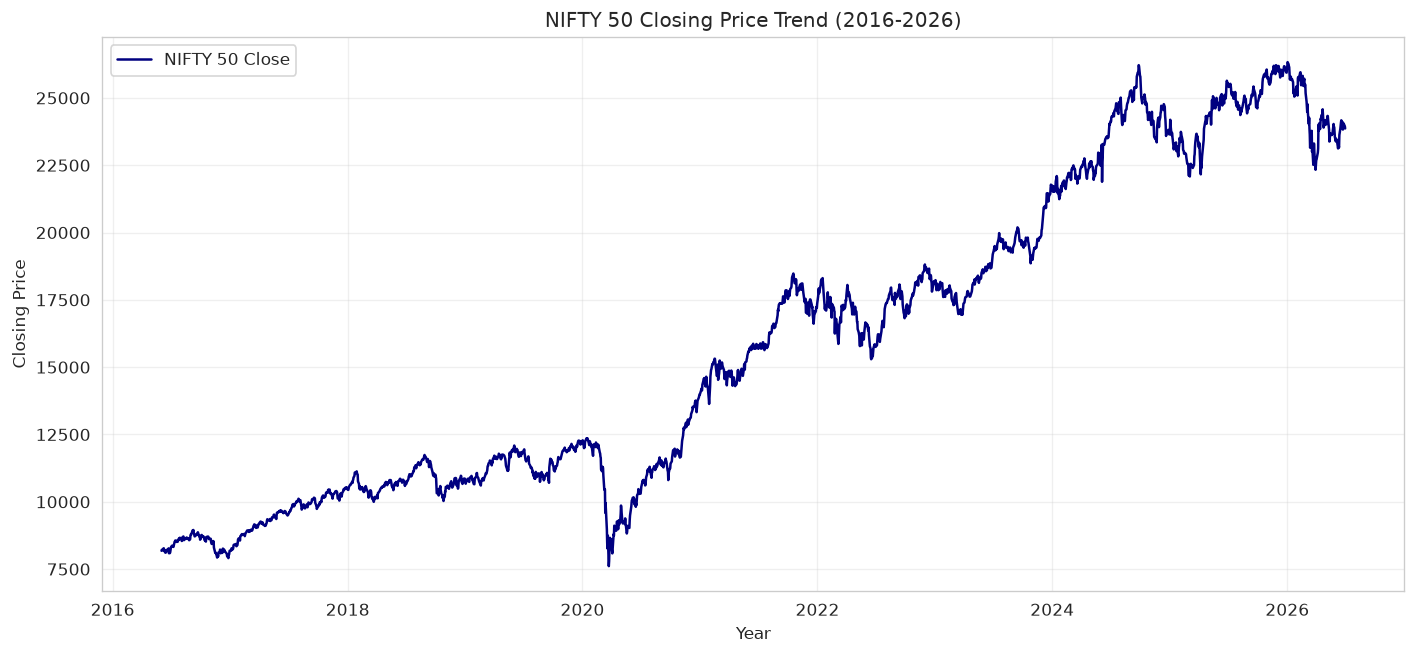

In [11]:
# nifty 50 trend over time
plt.figure(figsize=(14,6))

plt.plot(
    df_clean["Date"],
    df_clean["Close"],
    label="NIFTY 50 Close",
    color="navy"
)

plt.title("NIFTY 50 Closing Price Trend (2016-2026)")
plt.xlabel("Year")
plt.ylabel("Closing Price")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

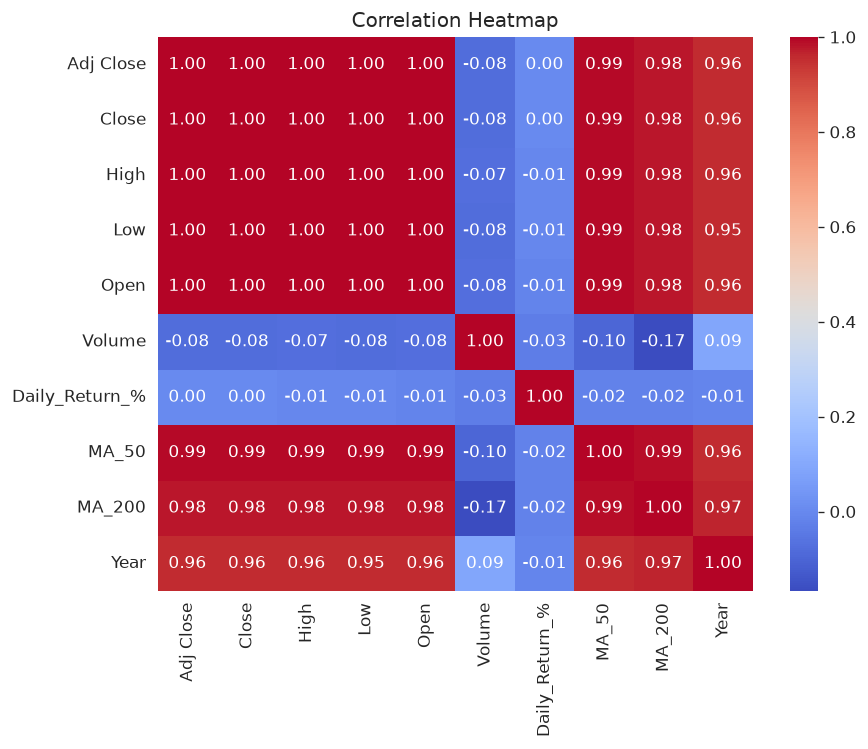

In [12]:
#correlation between variables
plt.figure(figsize=(8,6))

corr_matrix = df_clean.select_dtypes(include=np.number).corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

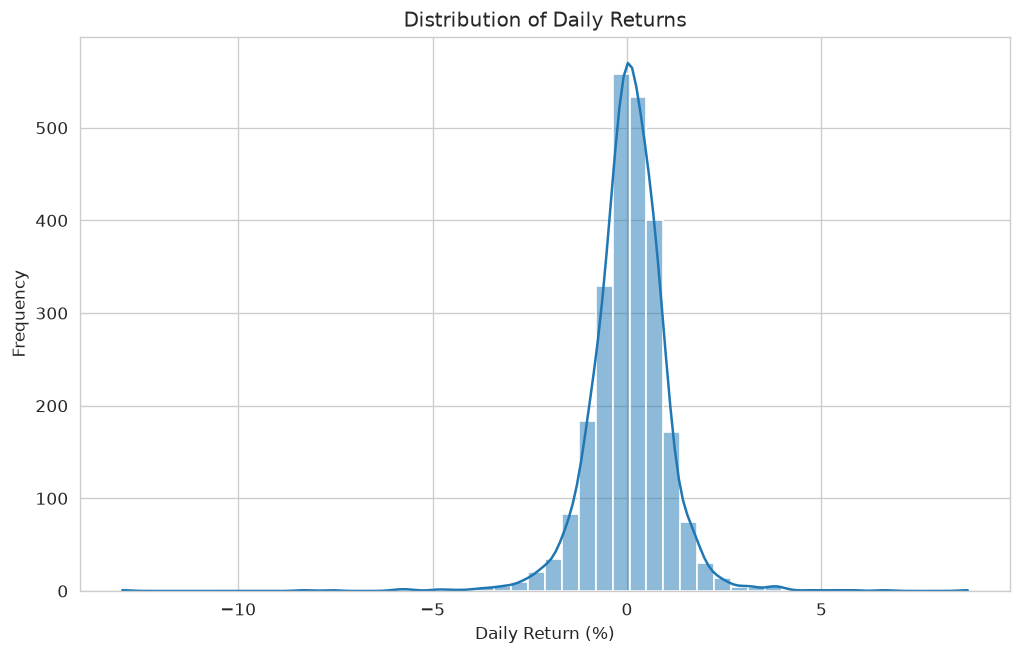

In [13]:
#EDA chart
plt.figure(figsize=(10,6))

sns.histplot(
    df_clean["Daily_Return_%"].dropna(),
    bins=50,
    kde=True
)

plt.title("Distribution of Daily Returns")
plt.xlabel("Daily Return (%)")
plt.ylabel("Frequency")

plt.show()

In [14]:
#cleaned data to save in file
df_clean.to_csv(
    "data/nifty_cleaned.csv",
    index=False
)

print("File saved successfully.")

File saved successfully.


In [15]:
#what we did in week 1 
print("WEEK 1 SUMMARY")
print("- Dataset successfully acquired from Yahoo Finance")
print("- Data quality audit completed")
print("- No missing values detected")
print("- No duplicate rows detected")
print("- OHLC consistency checks passed")
print("- Features engineered")
print("- EDA visualizations generated")
print("- Clean dataset exported")

WEEK 1 SUMMARY
- Dataset successfully acquired from Yahoo Finance
- Data quality audit completed
- No missing values detected
- No duplicate rows detected
- OHLC consistency checks passed
- Features engineered
- EDA visualizations generated
- Clean dataset exported
